# Chapter 0 — A market of currencies

A trader starts with 1,000 US dollars. She buys euros with them, uses the euros to buy pounds, and uses the pounds to buy dollars back. She ends up with 1,002.10 dollars. Nothing about the world changed, and she is 2.10 dollars richer. Where did the money come from?

A second puzzle. In 1985 Israel replaced its currency: 1000 old shekels became 1 *new* shekel. Overnight, every exchange rate involving the shekel changed by a factor of 1000. Did any trading opportunity appear or disappear? Which of the numbers on a currency board are *real*, and which are just a choice of units?

This chapter answers both questions. The language we build here (labels on the edges of a graph, products around loops, changes of units at the vertices) is the language of the whole course. Later chapters swap currencies for other groups and add probability. The ideas stay the same.

**What you'll learn**

- How to describe a currency market as a *board* with a *labeling*, and a round trip as a *loop product*.
- Why changing units (a *reframing*) moves every exchange rate but never changes a loop product.
- How to count the market's "real" numbers, and how to find arbitrage with a classic graph algorithm.

**Prerequisites:** none. We use graphs, logarithms and a little group theory: the positive real numbers under multiplication form a group, written $(\mathbb R_{>0},\times)$.

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import HTML

from lgt import *
from lgt import viz

viz.use_style()
G = PositiveReals()  # the label group of this chapter: (R_{>0}, x)

**Helpers for this chapter.** These are small drawing utilities: they write rates on edges, write each triangle's round-trip factor inside it, and mark edges in gold. You can skip reading them.

In [2]:
NAMES = ["USD", "EUR", "GBP", "JPY", "ILS"]
OFFSETS = {0: (0.0, -0.28), 1: (-0.3, 0.2), 2: (0.3, 0.2), 3: (0.3, -0.2), 4: (-0.3, -0.2)}

def rate_labels(U, sig=4):
    return [f"{x:.{sig}g}" for x in U]

def name_vertices(ax, board, names=NAMES, offsets=OFFSETS):
    for v, nm in enumerate(names):
        dx, dy = offsets.get(v, (0, 0.22))
        ax.text(*(board.pos[v] + (dx, dy)), nm, ha="center", va="center",
                fontsize=11, fontweight="bold", color=viz.INK, zorder=11)

def annotate_faces(ax, board, U, fmt="×{:.4f}"):
    for poly, x in zip(board.face_polys, face_products(G, board, U)):
        c = 0.72 * np.asarray(poly).mean(axis=0) + 0.28 * board.pos[0]   # pull toward the hub
        ax.text(*c, fmt.format(x), ha="center", va="center", fontsize=9, color=viz.INK,
                style="italic", zorder=7)

def mark_edges(ax, board, edges, color=viz.GOLD):
    for e in edges:
        (x0, y0), (x1, y1) = board.pos[board.edges[e]]
        ax.plot([x0, x1], [y0, y1], color=color, lw=9, alpha=0.45, zorder=2,
                solid_capstyle="round")

FACE_NORM = mpl.colors.Normalize(-0.006, 0.006)   # log of face product; 0 = pale

def draw_market(ax, board, U, title=None, faces=True, **kw):
    viz.draw_board(ax, board, U, G, edge_labels=rate_labels(U), faces=faces,
                   face_values=np.log(face_products(G, board, U)), face_cmap="RdBu_r",
                   face_norm=FACE_NORM, pad=0.55, title=title, **kw)
    name_vertices(ax, board)
    if faces:
        annotate_faces(ax, board, U)

## 0.1 The market as a board

Five currencies trade with each other: the US dollar, the euro, the British pound, the Japanese yen and the Israeli shekel. Not every pair trades directly. In our toy market every currency trades against the dollar, and the other four trade in a ring: EUR–GBP, GBP–JPY, JPY–ILS and ILS–EUR.

This is a graph. The **vertices** are the currencies, $V=\lbrace \text{USD},\text{EUR},\text{GBP},\text{JPY},\text{ILS}\rbrace$. The **edges** are the trading pairs, so $|E|=8$.

We also mark the four *triangles* of currencies in which all three pairs trade, such as USD–EUR–GBP. A triangle is a short round trip, and short round trips are where arbitrage hides. A graph together with a chosen list of closed walks is called a **board** $X$ (glossary 1.1), and the chosen closed walks are its **faces** (glossary 1.3). We write $F$ for the list of faces. Our board has $|F|=4$.

Each edge $\lbrace s,t\rbrace$ can be walked in two **directions**, $s\to t$ and $t\to s$ (glossary 1.2). We write $\vec E$ for the set of all directions. It has $|\vec E|=2|E|=16$ elements. For a direction $d$, $\bar d$ is the same edge walked the other way.

Board('market': 5 vertices, 8 edges, 4 faces)


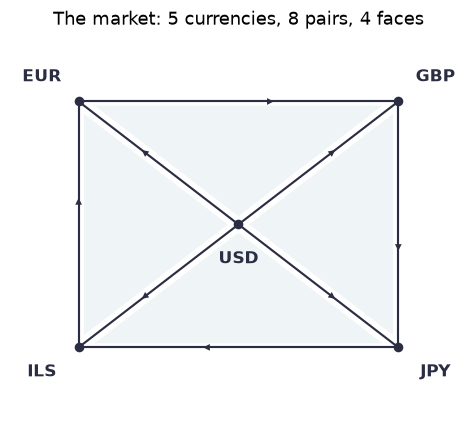

In [3]:
pos = [(0, 0), (-1.3, 1.0), (1.3, 1.0), (1.3, -1.0), (-1.3, -1.0)]
edges = [(0, 1), (0, 2), (0, 3), (0, 4),          # USD -> X   (the "spokes")
         (1, 2), (2, 3), (3, 4), (4, 1)]          # the ring EUR->GBP->JPY->ILS->EUR
triangles = [[0, 1, 2, 0], [0, 2, 3, 0], [0, 3, 4, 0], [0, 4, 1, 0]]
market = Board.from_vertex_cycles(5, edges, triangles, pos=pos, name="market",
                                  vertex_names=NAMES)
print(market)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
viz.draw_board(ax, market, pad=0.55, title="The market: 5 currencies, 8 pairs, 4 faces")
name_vertices(ax, market)
plt.show()

Look at the shaded triangles: those are the four faces. The small arrows show each edge's *reference orientation*. It is just a bookkeeping choice of which direction we store a number for, and it carries no meaning.

> **Recap.** A board $X$ is a graph $(V,E)$ plus a list $F$ of closed walks called faces. Every edge can be walked in two directions. In our market, vertices are currencies, edges are trading pairs and faces are triangles of currencies.

**Check yourself**

1. A new currency, the Swiss franc, starts trading only against the dollar. How many vertices, edges and faces does the board gain?

<details><summary>Answer</summary>

One vertex (CHF), one edge (USD–CHF) and no faces. A single new edge closes no new triangle.

</details>

2. If *every* pair of the five currencies traded directly, how many edges and triangles would there be?

<details><summary>Answer</summary>

$\binom52=10$ edges and $\binom53=10$ triangles.

</details>

## 0.2 Exchange rates are a labeling

An exchange rate is a positive number attached to a *direction*: $U(\text{USD}\to\text{JPY})=150$ means one dollar buys 150 yen.

The rates come from the group $G=(\mathbb R_{>0},\times)$ of positive numbers under multiplication. We call the group the labels come from the **label group** $G$ (glossary 2.1). Later chapters use other label groups. Formally, a **labeling** (glossary 2.2) is a function

$$
U:\vec E\to\mathbb R_{>0},\qquad U(\bar d)=U(d)^{-1}.
$$

The rule $U(\bar d)=U(d)^{-1}$ says that going back undoes going forward: if a dollar buys 150 yen, a yen buys $\tfrac{1}{150}$ dollar. Real markets break this rule slightly, because a dealer buys at one price and sells at a slightly worse one (the *bid/ask spread*). We ignore spreads and fees throughout. With that assumption, a labeling is just one positive number per edge, stored for its reference orientation. The reverse direction is forced.

Here is our market. The four spokes hold today's dollar rates. The ring rates are what you get by going through the dollar, **except** for one quote: EUR→GBP is quoted at 0.8605 instead of 0.79/0.92 ≈ 0.8587.

In [4]:
usd = {"EUR": 0.92, "GBP": 0.79, "JPY": 150.0, "ILS": 3.70}   # units of X per 1 USD
via_usd = lambda a, b: usd[b] / usd[a]                         # a -> b through the dollar
U = np.array([usd["EUR"], usd["GBP"], usd["JPY"], usd["ILS"],
              0.8605,                                          # EUR -> GBP (slightly off!)
              via_usd("GBP", "JPY"), via_usd("JPY", "ILS"), via_usd("ILS", "EUR")])

for e, (s, t) in enumerate(market.edges):
    print(f"{NAMES[s]}->{NAMES[t]}: {U[e]:>9.5g}     {NAMES[t]}->{NAMES[s]}: {1/U[e]:>9.5g}")

USD->EUR:      0.92     EUR->USD:     1.087
USD->GBP:      0.79     GBP->USD:    1.2658
USD->JPY:       150     JPY->USD: 0.0066667
USD->ILS:       3.7     ILS->USD:   0.27027
EUR->GBP:    0.8605     GBP->EUR:    1.1621
GBP->JPY:    189.87     JPY->GBP: 0.0052667
JPY->ILS:  0.024667     ILS->JPY:    40.541
ILS->EUR:   0.24865     EUR->ILS:    4.0217


> **Recap.** A labeling $U:\vec E\to\mathbb R_{>0}$ puts a rate on every direction, with the reverse direction carrying the inverse. It is stored as one number per edge, so $|E|$ numbers in total.

**Check yourself**

1. $U(\text{USD}\to\text{JPY})=150$. What is $U(\text{JPY}\to\text{USD})$?

<details><summary>Answer</summary>

$\tfrac{1}{150}\approx 0.00667$ dollars per yen.

</details>

2. With a bid/ask spread, what happens if you change dollars to yen and immediately back?

<details><summary>Answer</summary>

You lose a little: the two directions are no longer exact inverses, and their product is slightly below 1. That is exactly the rule $U(\bar d)=U(d)^{-1}$ failing. We assume it holds.

</details>

## 0.3 Routes and round trips: walk products

Converting money along a route multiplies the rates. Changing dollars to euros and then euros to pounds gives 0.92 × 0.8605 ≈ 0.7917 pounds per dollar.

For a walk $\gamma=(d_1,d_2,\dots,d_k)$, a sequence of directions where each one starts where the previous one ended, the **walk product** (glossary 2.3) is

$$
U(\gamma)=U(d_1)\,U(d_2)\cdots U(d_k)\in\mathbb R_{>0}.
$$

It answers the question: one unit of the starting currency becomes how many units of the final currency?

A **loop product** (glossary 2.4) is the walk product of a *closed* walk, one that ends where it started. It is a round trip: one unit of $v$ becomes $U(\gamma)$ units of $v$. **Arbitrage** is a round trip with $U(\gamma)\neq1$. If $U(\gamma)>1$ you walk $\gamma$. If $U(\gamma)<1$ you walk it backwards, which gives $U(\gamma)^{-1}>1$.

The loop product of a face $f$ is its **face product** $U_f\in\mathbb R_{>0}$ (glossary 2.5). A face with $U_f\neq1$ is a **defect**.

In [5]:
route = walk_product(G, market, U, [0, 1, 2])               # USD -> EUR -> GBP
trip = loop_product(G, market, U, [0, 1, 2, 0])            # ... -> USD
print(f"USD->EUR->GBP: one dollar becomes {route:.4f} pounds")
print(f"USD->EUR->GBP->USD: one dollar becomes {trip:.5f} dollars")
print("face products:", np.round(face_products(G, market, U), 5))
print("defects:      ", defects(G, market, U))

USD->EUR->GBP: one dollar becomes 0.7917 pounds
USD->EUR->GBP->USD: one dollar becomes 1.00210 dollars
face products: [1.0021 1.     1.     1.    ]
defects:       [ True False False False]


That is the trader's 2.10 dollars on 1,000: a round trip with factor 1.0021. In the picture, each face shows its face product. Defects are shaded red when the round trip (walked in the face's stored order) gains, and blue when it loses. Faces with no arbitrage are pale.

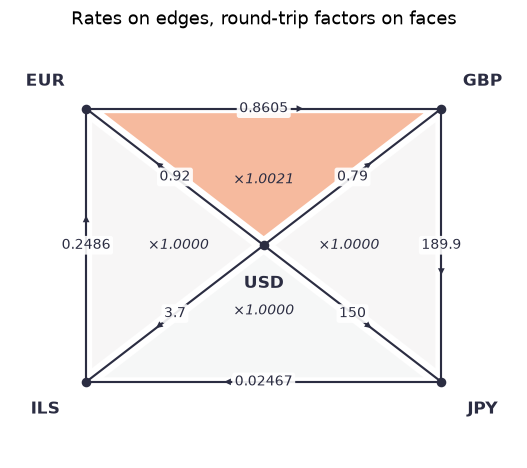

In [6]:
fig, ax = plt.subplots(figsize=(6, 5))
draw_market(ax, market, U, title="Rates on edges, round-trip factors on faces")
plt.show()

A **consistent** labeling (glossary 2.6) is one where *every* loop product is 1. In currency terms: no arbitrage anywhere. Our market is not consistent, and the only culprit is the top triangle.

> **Recap.** Walk products multiply rates along a route. Loop products are round trips, face products are round trips around faces, and a defect is a face whose round trip is not 1. Consistent means no arbitrage on any loop.

**Check yourself**

1. One shekel becomes how many yen along ILS→USD→JPY?

<details><summary>Answer</summary>

$\tfrac{1}{3.70}\times150\approx 40.5$ yen. The first step walks the USD→ILS edge backwards, so it uses the inverse rate.

</details>

2. A loop has product 1.003. What is the product of the same loop walked backwards?

<details><summary>Answer</summary>

$\tfrac{1}{1.003}$. Reversing a walk reverses the order of the factors and inverts each one. Arbitrage in one direction is a loss in the other.

</details>

3. What is the loop product of USD→EUR→USD, there and straight back?

<details><summary>Answer</summary>

Exactly $U\cdot U^{-1}=1$, always. A walk that only goes out and straight back can never carry arbitrage. A loop needs to go around a cycle of the graph.

</details>

## 0.4 Changing units: reframings

Back to 1985. Choose, for every currency $v$, a number

$$
h(v)=\text{how many old units make one new unit of }v,\qquad h(v)\in\mathbb R_{>0}.
$$

For the shekel, $h(\text{ILS})=1000$. Every other currency keeps its unit, so $h=1$ there. What happens to a rate $U(s\to t)$? One *new* unit of $s$ is $h(s)$ old units of $s$. Those buy $h(s)\,U(s\to t)$ old units of $t$, which is $h(s)\,U(s\to t)/h(t)$ new units of $t$. So

$$
U(s\to t)\ \longmapsto\ h(s)\,U(s\to t)\,h(t)^{-1}.
$$

A function $h:V\to\mathbb R_{>0}$ used this way is a **reframing** (glossary 3.1). The name says what it is: every currency changes its own convention, and a rate, being a conversion between two conventions, feels the change at both of its ends.

Let's check with 1985 numbers. If a dollar bought 1500 old shekels, it now buys $h(\text{USD})\cdot1500\cdot h(\text{ILS})^{-1}=\tfrac{1500}{1000}=1.5$ new shekels.

In [7]:
mini = Board.from_vertex_cycles(2, [(0, 1)], [])                # USD -> ILS, one edge
print("new rate:", reframe(G, mini, np.array([1500.0]), np.array([1.0, 1000.0])))

new rate: [1.5]


**Why loop products survive.** Walk two steps, $s\to v\to t$, after reframing:

$$
h(s)U(s\to v)h(v)^{-1}\cdot h(v)U(v\to t)h(t)^{-1}=h(s)\,\big[U(s\to v)U(v\to t)\big]\,h(t)^{-1}.
$$

The $h(v)$ in the middle cancels. Along any walk only the *endpoints* feel a reframing. For a round trip both endpoints are the same currency $v$, so the loop product becomes $h(v)\,U(\gamma)\,h(v)^{-1}=U(\gamma)$: numbers commute, and the factors cancel.

> **Fact 0.1 (round trips don't care about units).** For every reframing $h:V\to\mathbb R_{>0}$ and every closed walk $\gamma$, the loop product of the reframed labeling equals $U(\gamma)$.

Let's redenominate in two stages: first the shekel ($\times1000$), then also the yen ($\times100$) and the pound ($\times0.01$, so a "new pound" is a penny). Gold bars mark the edges whose rate changed.

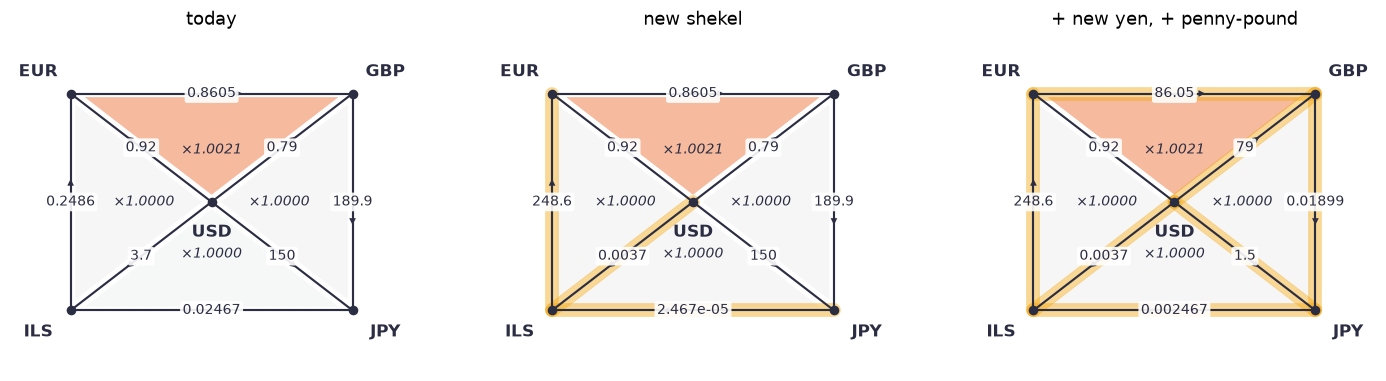

                     today: face products [1.002101 1.       1.       1.      ]
                new shekel: face products [1.002101 1.       1.       1.      ]
  + new yen, + penny-pound: face products [1.002101 1.       1.       1.      ]


In [8]:
h1 = np.array([1, 1, 1, 1, 1000.0])                    # order: USD EUR GBP JPY ILS
h2 = np.array([1, 1, 0.01, 100, 1000.0])
stages = [(U, "today", []), (reframe(G, market, U, h1), "new shekel", [3, 6, 7]),
          (reframe(G, market, U, h2), "+ new yen, + penny-pound", [1, 2, 3, 4, 5, 6, 7])]
fig, axs = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (V_, title, changed) in zip(axs, stages):
    mark_edges(ax, market, changed)
    draw_market(ax, market, V_, title=title)
plt.show()
for V_, title, _ in stages:
    print(f"{title:>26}: face products {np.round(face_products(G, market, V_), 6)}")

Compare the three panels. Almost every rate changes, and some by factors of a thousand. The italic numbers inside the triangles don't move, and neither do their colors.

The animation below makes the point continuously. Every currency's unit drifts up and down, so the rates on the edges churn while the triangles stay frozen.

In [9]:
from matplotlib.animation import FuncAnimation

amp = np.array([0.0, 0.7, 1.1, 0.9, 1.3])              # how far each unit drifts (log-scale)
phase = np.array([0.0, 0.5, 2.0, 3.5, 5.0])

def frame(k, ax, n=40):
    ax.clear()
    h = np.exp(amp * np.sin(2 * np.pi * k / n + phase))
    draw_market(ax, market, reframe(G, market, U, h), title="units drifting; round trips frozen")

fig, ax = plt.subplots(figsize=(5.5, 4.6), dpi=80)
anim = FuncAnimation(fig, frame, frames=40, fargs=(ax,), interval=120)
plt.close(fig)
with mpl.rc_context({"savefig.dpi": 72}):                # keep the saved notebook small
    html = anim.to_jshtml(default_mode="loop")
HTML(html)

> **Recap.** A reframing $h:V\to\mathbb R_{>0}$ changes the unit of every currency, and acts by $U(s\to t)\mapsto h(s)U(s\to t)h(t)^{-1}$. Along a walk the middle factors cancel, so round trips are untouched (Fact 0.1).

**Check yourself**

1. Japan introduces a new yen worth 100 old yen. A dollar used to buy 150 yen. What does it buy now?

<details><summary>Answer</summary>

$h(\text{JPY})=100$, so the new rate is $h(\text{USD})\cdot150\cdot h(\text{JPY})^{-1}=\tfrac{150}{100}=1.5$ new yen.

</details>

2. Which rates change when only the shekel is redenominated?

<details><summary>Answer</summary>

Exactly the three edges touching ILS: USD–ILS, JPY–ILS and ILS–EUR. An edge feels only the reframing at its two ends.

</details>

3. Every currency is redenominated by the *same* factor $c$. What happens to the rates?

<details><summary>Answer</summary>

Nothing: $c\,U\,c^{-1}=U$. A reframing that is the same everywhere does nothing at all, at least when the labels commute.

</details>

## 0.5 Same market, different units: classes and the numbers that are real

Two traders quote the same market, one in 1984 shekels and one in 1986 shekels. Every shekel rate on their screens differs, yet they are looking at the *same* market. We make this precise.

The **class** $[U]$ of a labeling (glossary 3.3) is the set of all labelings you can reach from $U$ by some reframing: "the same market, up to the choice of units." An **invariant** (glossary 3.4) is a function $f$ from labelings to numbers that no reframing can change, so it is really a function of the class. Fact 0.1 says loop products are invariants. The individual rates are not.

**How many of a market's numbers are real?** There are 8 rates and 5 currencies whose units you may choose. But one of those 5 choices is useless: scaling every unit by the same factor does nothing (question 3 above). So reframings can adjust 5 − 1 = 4 things, which leaves 8 − 4 = 4 numbers that units cannot touch. In general, for a connected board:

$$
\#\text{independent invariants}=|E|-|V|+1.
$$

This is exactly the number of independent cycles of the graph. In our market it is 8 − 5 + 1 = 4, one for each triangle.

**Seeing them: the tree normal form** (glossary 3.8). Pick a spanning tree, say the four spokes out of the dollar. Now choose the units so that every tree edge reads exactly 1: define the new unit of each currency to be "what one dollar buys." The tree edges now carry no information at all, and whatever is left on the other edges is real. For a non-tree edge it equals the loop product of the round trip "dollar → along the tree → across the edge → back along the tree."

tree edges: ['USD-EUR', 'USD-GBP', 'USD-JPY', 'USD-ILS']
reframing used (old units per new unit): {'USD': 1.0, 'EUR': 0.92, 'GBP': 0.79, 'JPY': 150.0, 'ILS': 3.7}


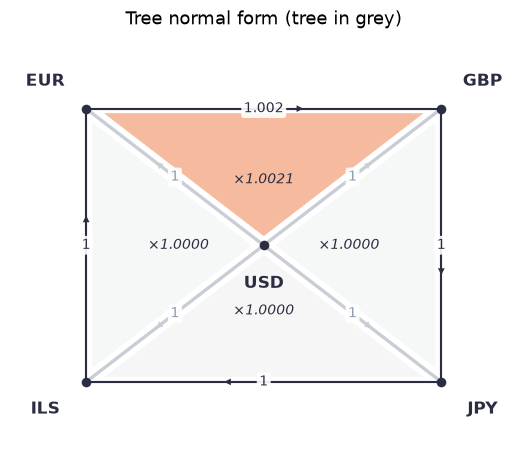

In [10]:
Un, h, tree = tree_normal_form(G, market, U, root=0)       # root 0 = USD
print("tree edges:", [f"{NAMES[s]}-{NAMES[t]}" for s, t in market.edges[tree]])
print("reframing used (old units per new unit):",
      {n: round(float(x), 4) for n, x in zip(NAMES, h)})

fig, ax = plt.subplots(figsize=(6, 5))
draw_market(ax, market, Un, tree_edges=tree, title="Tree normal form (tree in grey)")
plt.show()

Look at the grey spokes: all 1. Each ring edge now carries exactly the round-trip factor of the triangle next to it. The arbitrage was *spread* over the rates. The tree normal form *collects* it onto the edges outside the tree.

> **Fact 0.2 (tree normal form is a complete invariant).** Fix a spanning tree and a root. Every class contains exactly one labeling that is 1 on all tree edges. So two labelings describe the same market up to units if and only if they have the same tree normal form.

Let's check. Our three redenominated markets have the same tree normal form. A market with a genuinely different quote does not.

In [11]:
same = [tree_normal_form(G, market, V_)[0] for V_, _, _ in stages]
print("same class:", all(np.allclose(same[0], x) for x in same))
U_other = U.copy(); U_other[5] *= 1.01                   # change the GBP->JPY quote by 1%
print("different market, same class?",
      np.allclose(same[0], tree_normal_form(G, market, U_other)[0]))

same class: True
different market, same class? False


> **Recap.** A class is "the same market up to units". Invariants such as loop products are the real numbers, and there are $|E|-|V|+1$ independent ones. The tree normal form sets a spanning tree to 1 and leaves exactly those numbers on the remaining edges.

**Check yourself**

1. A connected market has 6 currencies and 9 trading pairs. How many numbers can no change of units affect?

<details><summary>Answer</summary>

$|E|-|V|+1=9-6+1=4$.

</details>

2. One trader quotes in dollars, the other in euros, and every rate on their screens differs. How can they check they see the same market?

<details><summary>Answer</summary>

Compare invariants. Either compare the loop products of a set of independent cycles, or put both labelings in tree normal form with the same tree and root and compare those (Fact 0.2).

</details>

3. Why does the tree normal form not need to choose a unit for the root currency?

<details><summary>Answer</summary>

Scaling every unit by the same factor changes nothing, so the root's unit is a free "global" choice that affects no rate. Fixing it at 1 just removes that redundancy.

</details>

## 0.6 No arbitrage means prices exist

When is a market consistent? Suppose every currency has a "price" $p(v)\in\mathbb R_{>0}$, its value in some common yardstick such as grams of gold. If rates are fair, $U(s\to t)=p(s)/p(t)$: one unit of $s$ is worth $p(s)$ grams, which buys $p(s)/p(t)$ units of $t$. Then every round trip telescopes to 1. The converse is the interesting part.

> **Fact 0.3 (no arbitrage ⟺ prices).** A labeling $U:\vec E\to\mathbb R_{>0}$ on a connected board is consistent if and only if there is $p:V\to\mathbb R_{>0}$ with $U(s\to t)=p(s)/p(t)$ for every edge. Equivalently, $U$ is a reframing of the all-ones labeling: $U(s\to t)=h(s)\cdot1\cdot h(t)^{-1}$ with $h=p$.

*Why:* if $U$ is consistent, put it in tree normal form. Every non-tree edge carries a loop product, which is 1, so the normal form is the all-ones labeling. Undo the reframing, and you have expressed $U$ as a reframing of all-ones.

Let's build a fair market from prices, check that it is consistent, and recover the prices from the rates alone.

In [12]:
p = np.array([1.0, 1.087, 1.266, 0.00667, 0.270])            # USD per unit: USD EUR GBP JPY ILS
fair = reframe(G, market, np.ones(market.n_edges), p)        # U(s->t) = p(s) / p(t)
print("consistent?", is_consistent(G, market, fair), "| our market?", is_consistent(G, market, U))
_, h_fair, _ = tree_normal_form(G, market, fair)
print("recovered prices:", np.round(1 / h_fair, 5))           # p = 1/h, with p(USD) = 1

consistent? True | our market? False
recovered prices: [1.      1.087   1.266   0.00667 0.27   ]


The prices come back exactly. Prices are unique only up to one common factor (the yardstick: dollars, gold, anything), which is once more the "global" reframing that does nothing.

In logarithms the statement becomes familiar. Write $a(d)=\log U(d)$, so $a:\vec E\to\mathbb R$. Consistency says that $a$ is a *difference of heights*: $a(s\to t)=\log p(s)-\log p(t)$. A consistent market is a landscape, and a rate tells you how far you step down. An inconsistent one is an impossible staircase, where walking in a circle you keep going down.

> **Recap.** No arbitrage on any loop means the rates come from prices, $U(s\to t)=p(s)/p(t)$. The prices are recovered by the tree normal form and are unique up to a common factor.

**Check yourself**

1. Prices in dollars are $p(\text{USD})=1$ and $p(\text{EUR})=1.087$. What is the fair $U(\text{USD}\to\text{EUR})$?

<details><summary>Answer</summary>

$p(\text{USD})/p(\text{EUR})=1/1.087\approx0.92$ euros per dollar.

</details>

2. Is the market of section 0.2 a reframing of the all-ones labeling?

<details><summary>Answer</summary>

No. It has a defect (the top triangle's factor is 1.0021, not 1), and reframings never change loop products.

</details>

## 0.7 Finding arbitrage is finding a negative cycle

Real markets have dozens of currencies and thousands of loops. Checking them one by one is hopeless. Logarithms turn the search into a classic graph problem. Give each direction $d$ the weight $w(d)=-\log U(d)$, so $w:\vec E\to\mathbb R$. Then a round trip is profitable exactly when its total weight is negative:

$$
U(\gamma)>1\iff \sum_{d\in\gamma}w(d)<0.
$$

So **an arbitrage loop is a negative-weight cycle**, and the Bellman–Ford algorithm finds one in $O(|V|\cdot|E|)$ time. (The usual trick of starting every vertex at distance 0 stands in for a virtual source connected to everyone.)

In [13]:
def bellman_ford_cycle(board, U):
    """A closed walk with loop product > 1, as (e, sign) steps, or None."""
    steps = [(e, s) for e in range(board.n_edges) for s in (1, -1)]
    dist, pred = np.zeros(board.n_vertices), [None] * board.n_vertices
    for _ in range(board.n_vertices):
        last = None
        for e, s in steps:
            a, b = board.step_endpoints(e, s)
            w = -s * np.log(U[e])                       # weight of the direction (e, s)
            if dist[a] + w < dist[b] - 1e-12:
                dist[b], pred[b], last = dist[a] + w, (e, s), b
        if last is None:
            return None                                 # no negative cycle: consistent
    return trace_cycle(board, pred, last)

In [14]:
def trace_cycle(board, pred, v):
    for _ in range(board.n_vertices):                   # step back until we are on the cycle
        v = board.step_endpoints(*pred[v])[0]
    cycle, u = [], v
    while True:
        cycle.append(pred[u])
        u = board.step_endpoints(*pred[u])[0]
        if u == v:
            return cycle[::-1]

A bigger market: seven currencies, every pair traded ($|E|=21$). We start from fair prices and add small quoting errors of about 0.1% to every rate. We use a random number generator *only* to fake those messy quotes. Nothing else in this chapter involves probability.

In [15]:
names7 = ["USD", "EUR", "GBP", "JPY", "ILS", "CHF", "CAD"]
p7 = np.array([1.0, 1.087, 1.266, 0.00667, 0.270, 1.13, 0.72])
K7 = Board.complete(7, names=names7)
noise = np.exp(np.random.default_rng(7).normal(0, 0.001, K7.n_edges))
quotes = reframe(G, K7, np.ones(K7.n_edges), p7) * noise
cyc = bellman_ford_cycle(K7, quotes)
route = [names7[v] for v in K7.walk_vertices(cyc)]
print(" -> ".join(route), f"| gain per round trip: {walk_product(G, K7, quotes, cyc):.5f}")
print("Bellman-Ford on the fair market:", bellman_ford_cycle(K7, reframe(G, K7, np.ones(21), p7)))

CAD -> CHF -> EUR -> CAD | gain per round trip: 1.00296
Bellman-Ford on the fair market: None


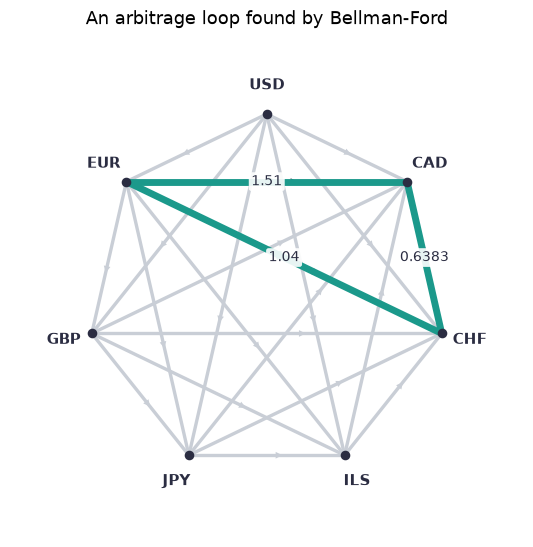

In [16]:
fig, ax = plt.subplots(figsize=(6, 6))
lab = {e: f"{(quotes[e] if s > 0 else 1 / quotes[e]):.4g}" for e, s in cyc}
others = [e for e in range(K7.n_edges) if e not in lab]      # drawn faint, like a tree
viz.draw_board(ax, K7, quotes, G, faces=False, edge_style="none", edge_labels=lab,
               tree_edges=others, highlight_walk=cyc, vertex_labels=names7, pad=0.45,
               title="An arbitrage loop found by Bellman-Ford")
plt.show()

The teal loop is a profitable round trip, with each rate printed in the direction you walk it. On the fair market, Bellman–Ford finds nothing, as Fact 0.3 says it must. (In real markets, spreads and fees eat such tiny gains, and fast traders remove what's left within moments. Markets stay *nearly* consistent because arbitrage is hunted.)

> **Recap.** With weights $-\log U(d)$, arbitrage loops are exactly negative cycles, and Bellman–Ford finds one or certifies that none exists.

**Check yourself**

1. Why $-\log U$ and not $\log U$?

<details><summary>Answer</summary>

Bellman–Ford hunts for *negative* cycles. A profitable loop has $\prod U>1$, i.e. $\sum\log U>0$, i.e. $\sum(-\log U)<0$.

</details>

2. If Bellman–Ford finds no negative cycle, what does Fact 0.3 tell you about the quotes?

<details><summary>Answer</summary>

There is no negative cycle in either direction of any loop, so every loop product is exactly 1. The market is consistent, and the rates come from prices.

</details>

## 0.8 Why there is no randomness here (yet)

The rest of the course puts *probability distributions* on labelings: "pick a labeling at random, but favor ones with few defects." That needs a starting point of pure ignorance, a **uniform** way of picking a label, one that looks the same after you change units (glossary 4.1).

For exchange rates that is impossible. A uniform choice of a positive number, unchanged by every rescaling $x\mapsto cx$, would have to give the intervals $[1,10)$, $[10,100)$, $[100,1000)$, … (and $[0.1,1)$, $[0.01,0.1)$, …) all the same probability. These infinitely many intervals cover all of $\mathbb R_{>0}$, so the total probability would be either 0 (if each gets 0) or infinite, never 1. It is the same reason there is no uniform distribution on all the integers. Chapter 2 calls the groups that *do* have a uniform distribution **compact**. $(\mathbb R_{>0},\times)$ is not one of them, and the library refuses to build a random labeling on it:

In [17]:
try:
    Model(market, G)
except ValueError as err:
    print("ValueError:", err)

ValueError: R>0 is not compact, so there is no uniform distribution to build a model on (see chapter 2).


Groups such as the circle of angles, or $\lbrace +1,-1\rbrace$, *do* have a uniform distribution, and chapter 2 builds random labelings on them.

## Chapter recap

- A **board** is a graph plus chosen closed walks (**faces**). A **labeling** $U:\vec E\to G$ puts a group element on each direction, with reverse = inverse. Here $G=(\mathbb R_{>0},\times)$ and labels are exchange rates.
- **Walk products** multiply labels along a route. **Loop products** are round trips, and a face with a nontrivial loop product is a **defect** (a triangle arbitrage).
- A **reframing** $h:V\to G$ changes units, $U(s\to t)\mapsto h(s)U(s\to t)h(t)^{-1}$. Middle factors telescope, so loop products are **invariants**.
- A **class** is "the same market up to units". It is pinned down by $|E|-|V|+1$ numbers, which the **tree normal form** displays on the non-tree edges.
- **Consistent** (no arbitrage) ⟺ rates come from prices ⟺ a reframing of the all-ones labeling.
- With weights $-\log U$, arbitrage is a negative cycle, which Bellman–Ford finds.
- $(\mathbb R_{>0},\times)$ has no uniform distribution, so randomness waits for compact groups.

## Dictionary

| Our term | Other names |
|---|---|
| board | lattice (physics); 2-complex (topology) |
| face | plaquette (physics); 2-cell (topology) |
| label group | gauge group (physics); gain group (gain graphs) |
| labeling | exchange rates; gauge field, link variables (physics); connection (geometry); gain function (gain graphs) |
| walk product | conversion along a route; parallel transport, Wilson line (physics) |
| loop product | round-trip factor; holonomy (geometry, physics) |
| defect | triangle arbitrage; nonzero curvature / field strength (physics) |
| reframing | redenomination, change of numeraire; gauge transformation (physics); switching (gain graphs) |
| consistent | no-arbitrage; flat, pure gauge (physics); balanced (gain graphs) |
| class | gauge orbit (physics); switching class (gain graphs) |
| invariant | (gauge-invariant) observable (physics) |
| tree normal form | gauge fixing, maximal-tree gauge (physics) |

*Prior art:* the physicist Kirill Ilinski built exactly this dictionary between arbitrage and gauge theory in *Physics of Finance* (1997, arXiv:hep-th/9710148).

## What's next

Exchange rates commute: $ab=ba$. Chapter 1 allows labels that don't, such as rotations of 3D space, where turning about one axis and then another is not the same as the reverse order. Loop products then *do* change under reframing, but only by a conjugation $h(v)\,U(\gamma)\,h(v)^{-1}$, and finding the true invariants becomes more interesting.